# Salifort Motors — Employee Turnover Analysis and Prediction

**Author:** Yago · **Tools:** Python, pandas, scikit-learn, XGBoost, seaborn

## 1. Project Overview

This notebook analyses an HR dataset from a fictional company, *Salifort Motors*,
to understand which factors are associated with employees leaving and to build a
classification model that flags employees at risk of turnover.

The project was originally developed as the capstone of the Google Advanced Data
Analytics Professional Certificate and has since been reworked as an independent
portfolio project: the analysis narrative, validation strategy and model
evaluation in this notebook are my own.

**Notebook structure**

1. Project Overview
2. Business Problem
3. Dataset Description
4. Data Cleaning and Preparation
5. Exploratory Data Analysis
6. Statistical Analysis
7. Feature Engineering
8. Modeling
9. Model Evaluation
10. Conclusions
11. Limitations and Future Work

## 2. Business Problem

Salifort Motors' HR department wants to improve employee retention. Replacing an
employee is costly (recruiting, onboarding, lost productivity), so HR wants to
answer two questions:

1. **Which factors are associated with employees leaving the company?**
2. **Can we identify employees who are likely to leave**, early enough for HR to
   intervene with voluntary retention actions?

**Framing.** This is a supervised binary classification problem with target
`left` (1 = employee left, 0 = stayed).

**Cost of errors.**

- *False negative* (an employee who leaves is not flagged): a missed
  opportunity to retain them — usually the more expensive error.
- *False positive* (an employee who stays is flagged): an unnecessary
  conversation or retention offer — cheaper, but excessive false alarms erode
  trust in the model.

Because of this asymmetry and the class imbalance, models are compared with
**recall, precision, F1 and PR-AUC** rather than accuracy.

**Ethical considerations.** Predictions should support voluntary retention
initiatives with human oversight, never automated employment decisions. Salary
and department are included as predictors only to explain turnover patterns; the
model should be audited for disparate impact before any real-world use.

## 3. Dataset Description

- **Source:** [HR Analytics and Job Prediction — Kaggle](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction)
  (file `HR_comma_sep.csv`).
- **Size:** 14,999 rows × 10 columns, one row per employee record.
- **Usage:** the dataset is **not redistributed** in this repository. Download it
  from Kaggle and place it in `data/raw/` (see the README).

| Variable | Description |
|---|---|
| `satisfaction_level` | Employee-reported job satisfaction [0–1] |
| `last_evaluation` | Score of the employee's last performance review [0–1] |
| `number_project` | Number of projects the employee contributes to |
| `average_montly_hours` | Average monthly working hours |
| `time_spend_company` | Years at the company (tenure) |
| `Work_accident` | Whether the employee had a work accident (0/1) |
| `left` | **Target** — whether the employee left (0/1) |
| `promotion_last_5years` | Whether the employee was promoted in the last 5 years (0/1) |
| `Department` | Department |
| `salary` | Salary band (`low`, `medium`, `high`) |

## 4. Data Cleaning and Preparation

### 4.1 Setup

Reusable logic (loading, cleaning, encoding, metrics) lives in `src/salifort/`
and is covered by unit tests in `tests/`. A single random seed is used
throughout for reproducibility.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from salifort.data import TARGET, clean_data, find_raw_data, load_raw_data
from salifort.evaluation import (
    CV_SCORING,
    best_f1_threshold,
    classification_metrics,
    compute_vif,
    cv_summary_from_scores,
    cv_summary_from_search,
)
from salifort.features import (
    POTENTIALLY_LEAKY_FEATURES,
    encode_features,
    split_features_target,
)

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)


def save_figure(fig, filename):
    """Save a figure to the figures/ folder for use in the README."""
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")

### 4.2 Load and inspect the raw data


In [8]:
raw_df = load_raw_data(find_raw_data(DATA_DIR))
print(f"Shape: {raw_df.shape}")
raw_df.head()

Shape: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [9]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [10]:
raw_df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.0000,14999.0000,14999.0000,14999.0000,14999.0000,14999.0000,14999.0000,14999.0000
mean,0.6128,0.7161,3.8031,201.0503,3.4982,0.1446,0.2381,0.0213
std,0.2486,0.1712,1.2326,49.9431,1.4601,0.3517,0.4259,0.1443
min,0.0900,0.3600,2.0000,96.0000,2.0000,0.0000,0.0000,0.0000
25%,0.4400,0.5600,3.0000,156.0000,3.0000,0.0000,0.0000,0.0000
50%,0.6400,0.7200,4.0000,200.0000,3.0000,0.0000,0.0000,0.0000
75%,0.8200,0.8700,5.0000,245.0000,4.0000,0.0000,0.0000,0.0000
max,1.0000,1.0000,7.0000,310.0000,10.0000,1.0000,1.0000,1.0000


All numeric columns are within plausible ranges (satisfaction and evaluation in
[0, 1], monthly hours between 96 and 310) and there are no missing values, as
checked below.

### 4.3 Standardise column names, missing values and duplicates

Column names are converted to `snake_case` and misspellings are fixed
(`average_montly_hours` → `average_monthly_hours`, `time_spend_company` →
`tenure`).

In [11]:
print("Missing values per column:")
print(raw_df.isna().sum())
print(f"\nExact duplicate rows: {raw_df.duplicated().sum():,} "
      f"({raw_df.duplicated().mean():.1%} of the data)")

Missing values per column:
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Department               0
salary                   0
dtype: int64

Exact duplicate rows: 3,008 (20.1% of the data)


About 20% of the rows are exact duplicates across all ten columns. With two
continuous variables (satisfaction and evaluation scores) it is very unlikely
that different employees share identical values on every field, so duplicates
are treated as repeated records and removed, keeping the first occurrence.

*Caveat:* the dataset has no employee ID, so this cannot be verified. Keeping
duplicates would also risk the same record appearing in both the training and
test sets, inflating test performance.

In [12]:
df = clean_data(raw_df)
print(f"Rows after removing duplicates: {len(df):,}")
df.head()

Rows after removing duplicates: 11,991


,satisfaction_level,last_evaluation,number_of_projects,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


### 4.4 Outliers

`tenure` is the only variable with values outside the 1.5 × IQR rule.

Upper limit: 5.5 years — outliers: 824 rows


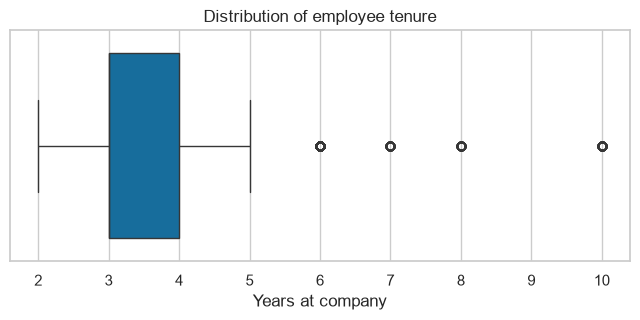

In [13]:
q1, q3 = df["tenure"].quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)
tenure_outliers = df["tenure"] > upper_limit
print(f"Upper limit: {upper_limit} years — outliers: {tenure_outliers.sum():,} rows")

fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=df["tenure"], ax=ax)
ax.set(title="Distribution of employee tenure", xlabel="Years at company")
plt.show()

The 824 employees with more than 5.5 years at the company are valid
observations, not data errors, and they carry information (none of them left,
see the EDA). They are **kept**: tree-based models are robust to them, and in
the logistic regression features are standardised.

## 5. Exploratory Data Analysis

### 5.1 Target balance

In [14]:
target_summary = pd.DataFrame({
    "employees": df[TARGET].value_counts(),
    "share": df[TARGET].value_counts(normalize=True),
}).rename(index={0: "stayed", 1: "left"})
target_summary

,employees,share
left,,
stayed,10000,0.834
left,1991,0.166


About 16.6% of employees left (1,991 of 11,991). The classes are imbalanced but
not extremely so; stratified splits and class-aware metrics are used from here
on.

### 5.2 Satisfaction

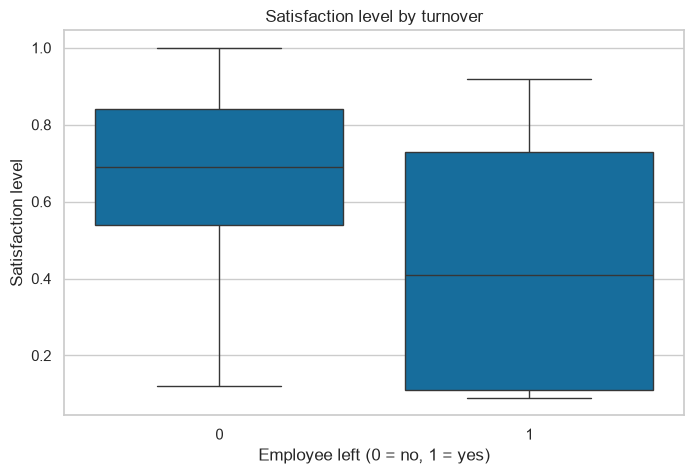

left
0    0.69
1    0.41
Name: satisfaction_level, dtype: float64

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET, y="satisfaction_level", ax=ax)
ax.set(title="Satisfaction level by turnover",
       xlabel="Employee left (0 = no, 1 = yes)", ylabel="Satisfaction level")
save_figure(fig, "satisfaction_by_turnover.png")
plt.show()

df.groupby(TARGET)["satisfaction_level"].median()

Employees who left reported markedly lower satisfaction (median 0.41 vs 0.69).

### 5.3 Workload: monthly hours and number of projects

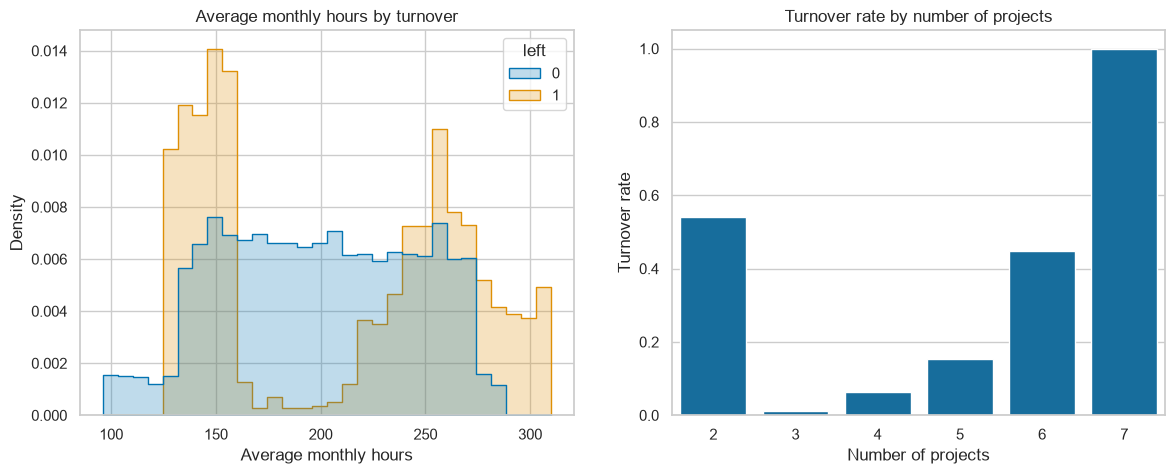

,turnover_rate,employees
number_of_projects,,
2,0.5417,1582
3,0.0108,3520
4,0.0643,3685
5,0.1536,2233
6,0.4492,826
7,1.0000,145


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="average_monthly_hours", hue=TARGET, bins=30,
             stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Average monthly hours by turnover",
            xlabel="Average monthly hours", ylabel="Density")

project_turnover = df.groupby("number_of_projects")[TARGET].mean()
sns.barplot(x=project_turnover.index, y=project_turnover.values, ax=axes[1])
axes[1].set(title="Turnover rate by number of projects",
            xlabel="Number of projects", ylabel="Turnover rate")

save_figure(fig, "workload_by_turnover.png")
plt.show()

df.groupby("number_of_projects")[TARGET].agg(turnover_rate="mean", employees="size")

Workload shows a **non-linear** relationship with turnover:

- Employees who left concentrate around ~130–160 hours/month (under-utilised)
  and ~240–310 hours/month (overworked).
- Turnover is lowest with 3–4 projects (1–6%), rises with 2 projects (54%) and
  6 projects (45%), and **every** employee with 7 projects left (145 of 145).

A linear model with a single coefficient per feature cannot capture this
U-shape, which anticipates the gap between linear and tree-based models.

### 5.4 Satisfaction vs. performance evaluation

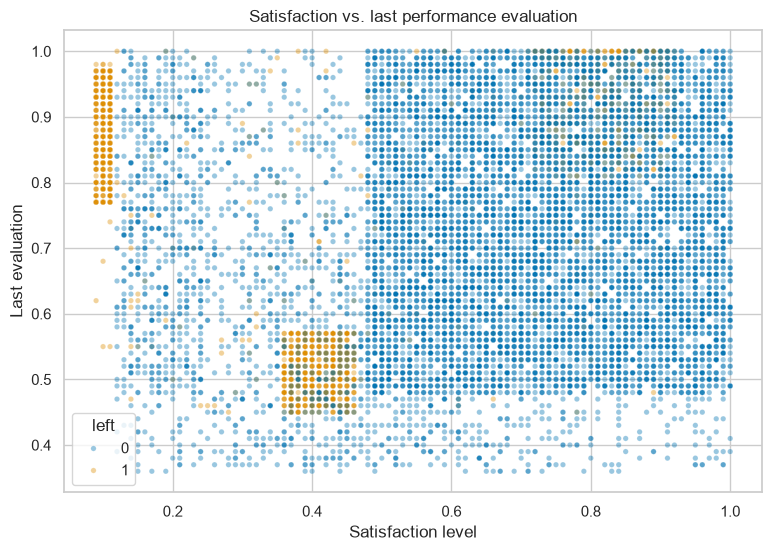

In [17]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="satisfaction_level", y="last_evaluation",
                hue=TARGET, alpha=0.4, s=15, ax=ax)
ax.set(title="Satisfaction vs. last performance evaluation",
       xlabel="Satisfaction level", ylabel="Last evaluation")
save_figure(fig, "satisfaction_vs_evaluation.png")
plt.show()

Leavers form distinct clusters rather than a single profile:

1. Very low satisfaction (~0.1) with high evaluations — likely overworked
   high performers.
2. Low-to-mid satisfaction (~0.35–0.45) with low evaluations.
3. High satisfaction (~0.7–0.9) with high evaluations.

Such sharply bounded clusters are unusual in real HR data and suggest the data
may be synthetic (see Limitations).

### 5.5 Tenure, salary, department and promotions

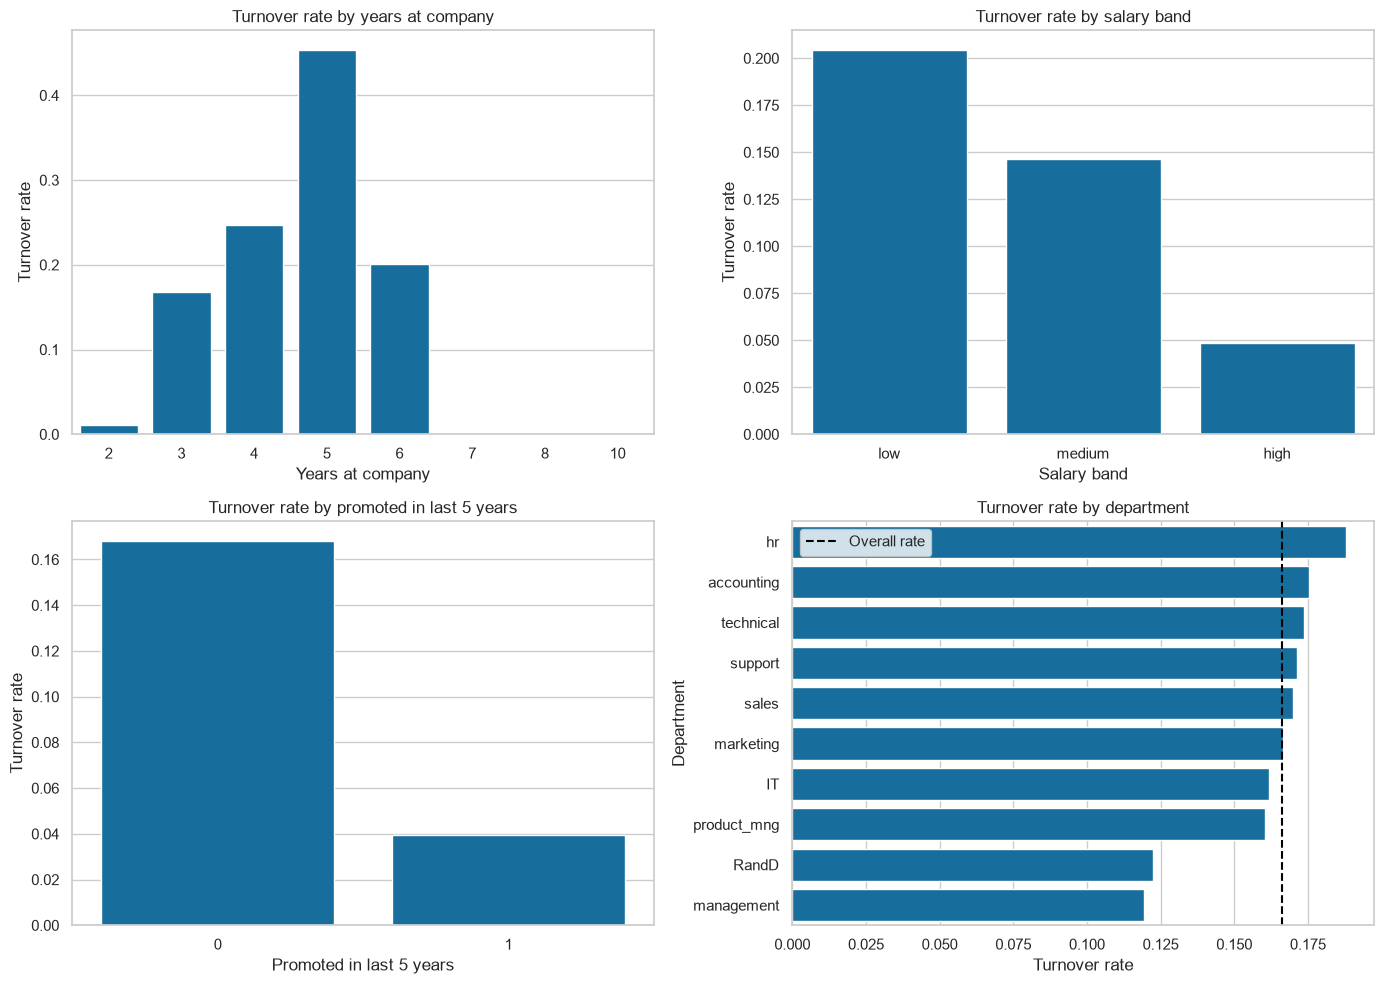

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

rate_by = {
    "tenure": df.groupby("tenure")[TARGET].mean(),
    "salary": df.groupby("salary")[TARGET].mean().reindex(["low", "medium", "high"]),
    "promotion_last_5years": df.groupby("promotion_last_5years")[TARGET].mean(),
}
labels = {"tenure": "Years at company", "salary": "Salary band",
          "promotion_last_5years": "Promoted in last 5 years"}

for ax, (column, rates) in zip(axes.flat[:3], rate_by.items()):
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax)
    ax.set(title=f"Turnover rate by {labels[column].lower()}",
           xlabel=labels[column], ylabel="Turnover rate")

department_rate = df.groupby("department")[TARGET].mean().sort_values(ascending=False)
sns.barplot(x=department_rate.values, y=department_rate.index, ax=axes.flat[3])
axes.flat[3].axvline(df[TARGET].mean(), color="black", linestyle="--",
                     label="Overall rate")
axes.flat[3].set(title="Turnover rate by department",
                 xlabel="Turnover rate", ylabel="Department")
axes.flat[3].legend()

plt.tight_layout()
save_figure(fig, "turnover_by_category.png")
plt.show()

- **Tenure:** turnover rises from 1% at 2 years to 45% at 5 years, then falls;
  no employee with 7 or more years left.
- **Salary:** turnover is 20.5% in the low band, 14.6% in medium and 4.8% in
  high.
- **Promotion:** 3.9% of promoted employees left vs. 16.8% of those not
  promoted — but only 203 employees (1.7%) were promoted.
- **Department:** rates range from 11.9% (management) to 18.8% (HR); the
  differences are small compared with the other factors.

### 5.6 Correlations

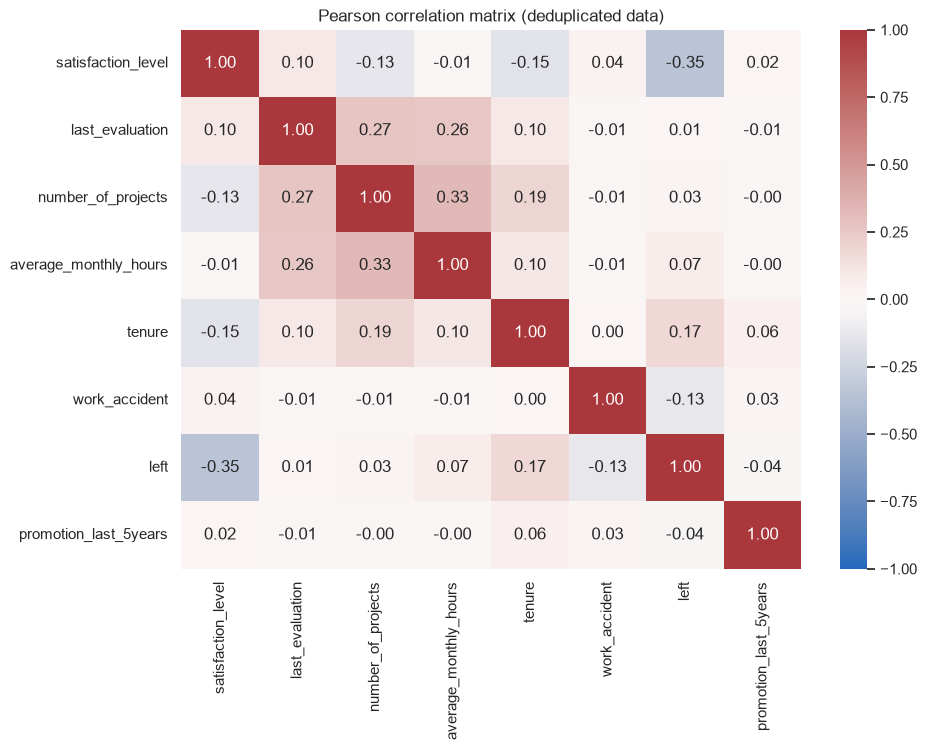

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), vmin=-1, vmax=1, annot=True, fmt=".2f",
            cmap="vlag", ax=ax)
ax.set_title("Pearson correlation matrix (deduplicated data)")
plt.show()

On the deduplicated data, satisfaction has the strongest linear correlation
with turnover (r ≈ −0.35), followed by tenure (r ≈ 0.17) and work accidents
(r ≈ −0.13). Workload variables show near-zero *linear* correlation with
turnover despite the strong patterns in §5.3: Pearson correlation only captures
monotonic linear relationships, not U-shaped ones.

No pair of predictors is strongly correlated (|r| < 0.5), so severe
multicollinearity is not expected; this is confirmed with VIF in §7.

## 6. Statistical Analysis

Two hypothesis tests check that the main EDA differences are not attributable to
chance. With ~12,000 observations even tiny effects are significant, so **effect
sizes** are reported alongside p-values. These tests describe associations, not
causal effects.

- **Satisfaction vs. turnover** — Mann–Whitney U test (satisfaction is not
  normally distributed), effect size: rank-biserial correlation.
- **Salary band and department vs. turnover** — chi-square test of
  independence, effect size: Cramér's V.

In [20]:
left_mask = df[TARGET] == 1
mw = stats.mannwhitneyu(df.loc[left_mask, "satisfaction_level"],
                        df.loc[~left_mask, "satisfaction_level"],
                        alternative="two-sided")
rank_biserial = 2 * mw.statistic / (left_mask.sum() * (~left_mask).sum()) - 1
print(f"Satisfaction — Mann-Whitney U p-value: {mw.pvalue:.2e}, "
      f"rank-biserial r: {rank_biserial:.3f}")


def cramers_v(contingency):
    chi2 = stats.chi2_contingency(contingency)
    n = contingency.to_numpy().sum()
    v = np.sqrt(chi2.statistic / (n * (min(contingency.shape) - 1)))
    return chi2.pvalue, v


for column in ["salary", "department"]:
    p_value, v = cramers_v(pd.crosstab(df[column], df[TARGET]))
    print(f"{column:<11}— chi-square p-value: {p_value:.2e}, Cramér's V: {v:.3f}")

Satisfaction — Mann-Whitney U p-value: 2.24e-266, rank-biserial r: -0.494
salary     — chi-square p-value: 8.98e-39, Cramér's V: 0.121
department — chi-square p-value: 1.33e-02, Cramér's V: 0.042


- Satisfaction differs significantly between leavers and stayers, with a
  **large** effect (rank-biserial r ≈ −0.49).
- Salary band is associated with turnover, with a **small** effect
  (Cramér's V ≈ 0.12).
- Department is statistically significant at the 5% level (p ≈ 0.013) but the
  effect is **negligible** (Cramér's V ≈ 0.04), consistent with the EDA.

## 7. Feature Engineering

- `salary` is ordinal → encoded as 0 (low), 1 (medium), 2 (high).
- `department` is nominal → one-hot encoded with one reference category dropped
  (`drop_first=True`), avoiding the dummy variable trap in the logistic
  regression.
- No scaling is applied here: scaling is done **inside** the logistic regression
  pipeline so that it is fitted only on training folds (no data leakage).

The data is then split once into training (75%) and test (25%) sets, stratified
on the target. **All model selection uses 5-fold stratified cross-validation on
the training set**; the test set is used only for the final evaluation.

In [21]:
model_df = encode_features(df)
X, y = split_features_target(model_df)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Features: {X.shape[1]}")
print(f"Train: {X_train.shape[0]:,} rows — positive rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape[0]:,} rows — positive rate {y_test.mean():.3f}")

Features: 17
Train: 8,993 rows — positive rate 0.166
Test:  2,998 rows — positive rate 0.166


### 7.1 Multicollinearity check (VIF)

Variance Inflation Factors are computed on the training features. Values above
~5–10 would indicate problematic multicollinearity for the logistic regression
coefficients.

In [22]:
vif = compute_vif(X_train)
vif.to_frame().head(10)

,VIF
dept_sales,3.1629
dept_technical,2.6939
dept_support,2.4536
dept_product_mng,1.6211
dept_RandD,1.6170
dept_marketing,1.6058
dept_accounting,1.5521
dept_hr,1.5360
dept_management,1.3971
number_of_projects,1.2198


All VIF values are below 3.2, far from the usual 5–10 warning range, so
multicollinearity is not a concern for the logistic regression coefficients.
Dropping one department category was enough to remove the perfect collinearity
that full one-hot encoding would have introduced.

## 8. Modeling

Three models of increasing flexibility are compared:

| Model | Why |
|---|---|
| Logistic regression | Interpretable linear baseline |
| Random forest | Captures non-linearities and interactions; robust to outliers |
| XGBoost | Gradient boosting, typically strong on tabular data |

All models handle the class imbalance (`class_weight="balanced"` or
`scale_pos_weight`) and are tuned or evaluated with the same cross-validation
splits. Hyperparameters are selected by **cross-validated F1**, which balances
missed leavers (recall) and false alarms (precision).

### 8.1 Logistic regression (baseline)

In [23]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000,
                       random_state=RANDOM_STATE),
)
log_reg_cv = cross_validate(log_reg, X_train, y_train, cv=cv,
                            scoring=CV_SCORING, n_jobs=-1)
log_reg.fit(X_train, y_train)

pd.DataFrame([cv_summary_from_scores("Logistic regression", log_reg_cv)])

,model,cv_precision,cv_precision_std,cv_recall,cv_recall_std,cv_f1,cv_f1_std,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,cv_pr_auc_std
0,Logistic regression,0.4047,0.0106,0.8218,0.0298,0.5422,0.015,0.8344,0.0096,0.3738,0.0114


The logistic regression reaches a cross-validated recall of 0.82 but a precision
of only 0.40 (F1 0.54, PR-AUC 0.37): it catches most leavers at the cost of many
false alarms. This is expected after the EDA — workload and tenure have
U-shaped relationships with turnover that a linear model on the log-odds cannot
represent without engineered features. It remains useful as an interpretable
baseline that shows how much the non-linear models add.

### 8.2 Random forest

In [24]:
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={
        "n_estimators": [200, 500],
        "max_depth": [5, 10, None],
        "max_features": ["sqrt", 1.0],
        "min_samples_leaf": [1, 2, 4],
    },
    scoring=CV_SCORING,
    refit="f1",
    cv=cv,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
pd.DataFrame([cv_summary_from_search("Random forest", rf_search)])

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}


,model,cv_precision,cv_precision_std,cv_recall,cv_recall_std,cv_f1,cv_f1_std,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,cv_pr_auc_std
0,Random forest,0.9744,0.0095,0.9136,0.0195,0.9429,0.0107,0.9823,0.0063,0.9629,0.011


### 8.3 XGBoost

In [25]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_search = GridSearchCV(
    estimator=XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                            scale_pos_weight=scale_pos_weight,
                            random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={
        "n_estimators": [200, 500],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.05, 0.1],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.8, 1.0],
    },
    scoring=CV_SCORING,
    refit="f1",
    cv=cv,
    n_jobs=-1,
)
xgb_search.fit(X_train, y_train)

print("Best parameters:", xgb_search.best_params_)
pd.DataFrame([cv_summary_from_search("XGBoost", xgb_search)])

Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 200, 'subsample': 1.0}


,model,cv_precision,cv_precision_std,cv_recall,cv_recall_std,cv_f1,cv_f1_std,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,cv_pr_auc_std
0,XGBoost,0.9652,0.0074,0.9263,0.0208,0.9452,0.0113,0.9833,0.0048,0.9656,0.0084


### 8.4 Model selection (cross-validation only)

The model is selected using cross-validated metrics on the training set. The
test set has not been used so far.

In [26]:
models = {
    "Logistic regression": log_reg,
    "Random forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}
cv_results = pd.DataFrame([
    cv_summary_from_scores("Logistic regression", log_reg_cv),
    cv_summary_from_search("Random forest", rf_search),
    cv_summary_from_search("XGBoost", xgb_search),
]).set_index("model")

metric_columns = [f"cv_{metric}" for metric in CV_SCORING]
display(cv_results[metric_columns].round(4))
display(cv_results[[f"{c}_std" for c in metric_columns]].round(4))

selected_model_name = cv_results["cv_f1"].idxmax()
selected_model = models[selected_model_name]
print(f"Selected model (highest CV F1): {selected_model_name}")

,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
model,,,,,
Logistic regression,0.4047,0.8218,0.5422,0.8344,0.3738
Random forest,0.9744,0.9136,0.9429,0.9823,0.9629
XGBoost,0.9652,0.9263,0.9452,0.9833,0.9656


,cv_precision_std,cv_recall_std,cv_f1_std,cv_roc_auc_std,cv_pr_auc_std
model,,,,,
Logistic regression,0.0106,0.0298,0.0150,0.0096,0.0114
Random forest,0.0095,0.0195,0.0107,0.0063,0.0110
XGBoost,0.0074,0.0208,0.0113,0.0048,0.0084


Selected model (highest CV F1): XGBoost


Both tree-based models clearly outperform the baseline (CV F1 ≈ 0.94–0.95 vs
0.54). XGBoost is selected with the highest mean CV F1 (0.945 vs 0.943 for the
random forest), but the gap is much smaller than the fold-to-fold standard
deviation (≈ 0.011), so **the two models are practically equivalent** on this
data. XGBoost also has a slightly higher CV PR-AUC (0.966 vs 0.963).

### 8.5 Decision threshold

The default 0.5 threshold is not necessarily optimal. The threshold that
maximises F1 is chosen from **out-of-fold predictions on the training set**, so
the test set remains untouched. HR could choose a lower threshold if missing a
leaver is considered much more costly than a false alarm.

In [27]:
oof_proba = cross_val_predict(clone(selected_model), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
tuned_threshold = best_f1_threshold(y_train, oof_proba)

threshold_comparison = pd.DataFrame([
    classification_metrics(y_train, oof_proba, threshold=0.5),
    classification_metrics(y_train, oof_proba, threshold=tuned_threshold),
], index=["default (0.5)", "F1-optimal"])
threshold_comparison.round(4)

,threshold,precision,recall,f1,accuracy,roc_auc,pr_auc
default (0.5),0.5000,0.9651,0.9263,0.9453,0.9822,0.9828,0.9652
F1-optimal,0.7849,0.9856,0.9190,0.9511,0.9843,0.9828,0.9652


On out-of-fold predictions, the F1-optimal threshold is ≈ 0.78. Compared with
0.5 it trades a small loss in recall (0.926 → 0.919) for higher precision
(0.965 → 0.986), increasing F1 from 0.945 to 0.951. The gain is modest: the
model's probabilities are already well separated. If HR valued recall more, a
lower threshold could be chosen from the same curve.

## 9. Model Evaluation

### 9.1 Final evaluation on the test set

The selected model is evaluated **once** on the held-out test set, using the
threshold chosen in §8.5. The other models are shown at the default threshold
for reference only; they played no part in the selection.

In [28]:
test_rows = []
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    threshold = tuned_threshold if name == selected_model_name else 0.5
    test_rows.append({"model": name, **classification_metrics(y_test, proba, threshold)})

test_results = pd.DataFrame(test_rows).set_index("model")
test_results.round(4)

,threshold,precision,recall,f1,accuracy,roc_auc,pr_auc
model,,,,,,,
Logistic regression,0.5000,0.4151,0.8193,0.5510,0.7782,0.8431,0.3857
Random forest,0.5000,0.9850,0.9237,0.9534,0.9850,0.9795,0.9632
XGBoost,0.7849,0.9872,0.9257,0.9554,0.9857,0.9845,0.9682


In [29]:
selected_test_proba = selected_model.predict_proba(X_test)[:, 1]
selected_test_pred = (selected_test_proba >= tuned_threshold).astype(int)
print(classification_report(y_test, selected_test_pred,
                            target_names=["Stayed", "Left"], digits=3))

              precision    recall  f1-score   support

      Stayed      0.985     0.998     0.991      2500
        Left      0.987     0.926     0.955       498

    accuracy                          0.986      2998
   macro avg      0.986     0.962     0.973      2998
weighted avg      0.986     0.986     0.985      2998



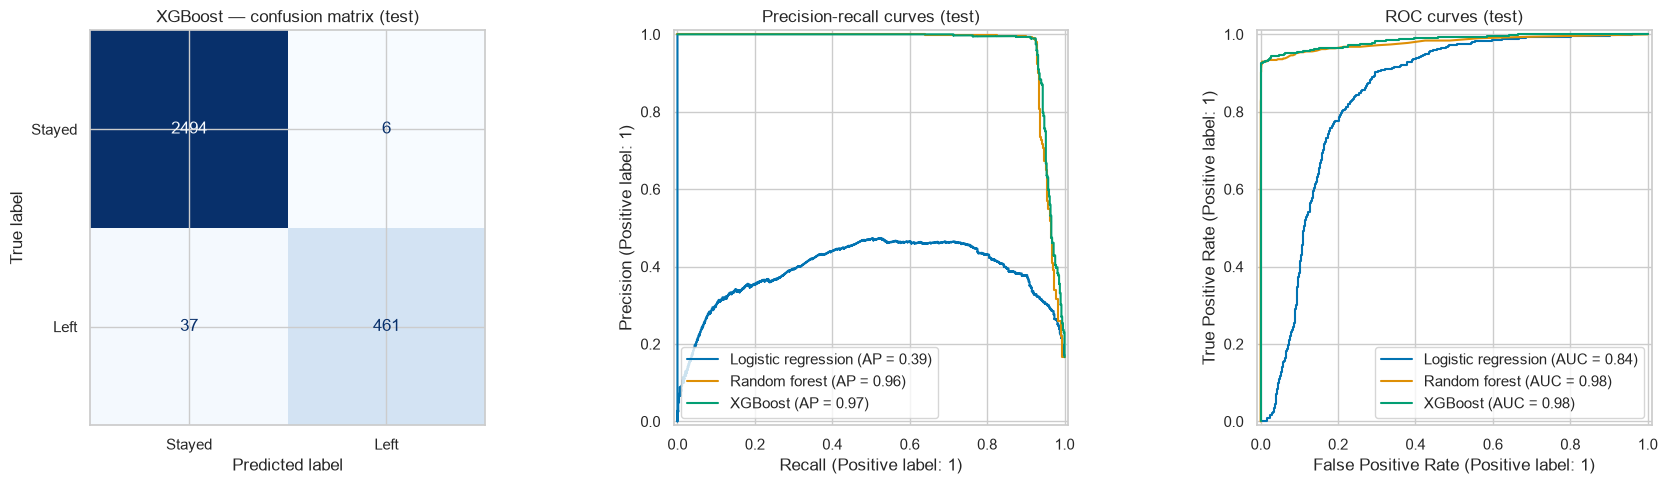

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, selected_test_pred, display_labels=["Stayed", "Left"],
    values_format="d", cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"{selected_model_name} — confusion matrix (test)")

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[2])
axes[1].set_title("Precision-recall curves (test)")
axes[2].set_title("ROC curves (test)")

plt.tight_layout()
save_figure(fig, "test_evaluation.png")
plt.show()

On the held-out test set the selected XGBoost model (threshold 0.78) achieves
**precision 0.987, recall 0.926, F1 0.955 and PR-AUC 0.968**, in line with its
cross-validation estimates (F1 0.951 on out-of-fold predictions), so there is
no sign of overfitting to the training data.

Of the 498 employees in the test set who left, the model identifies 461 and
misses 37; only 6 of the 2,500 employees who stayed are wrongly flagged.

The random forest obtains almost the same test results (F1 0.953 at the default
threshold), confirming the CV conclusion that both models are equivalent. The
logistic regression stays far behind (F1 0.55, PR-AUC 0.39), as the PR curves
show.

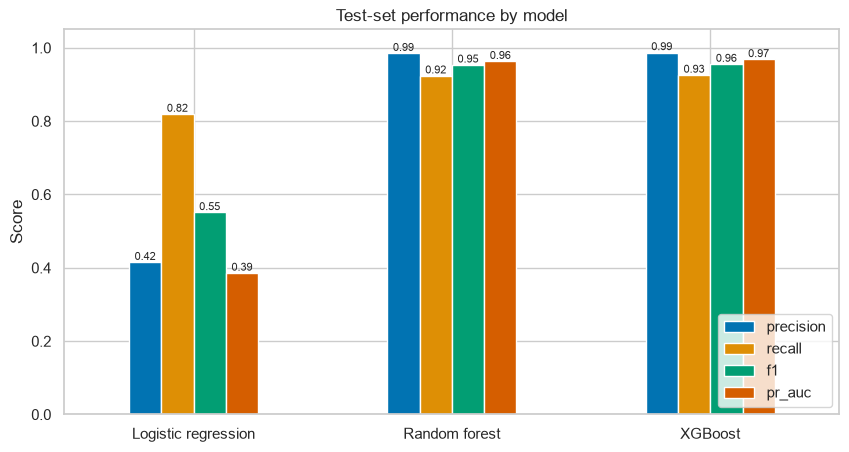

In [31]:
comparison = test_results[["precision", "recall", "f1", "pr_auc"]]
ax = comparison.plot(kind="bar", figsize=(10, 5), rot=0, ylim=(0, 1.05))
ax.set(title="Test-set performance by model", xlabel="", ylabel="Score")
ax.legend(loc="lower right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
save_figure(ax.figure, "model_comparison.png")
plt.show()

### 9.2 Feature importance

Permutation importance measures how much the test-set F1 drops when each
feature is randomly shuffled. Unlike impurity- or gain-based importance, it is
model-agnostic and not biased towards high-cardinality features. Importance
indicates predictive contribution, **not causation**.

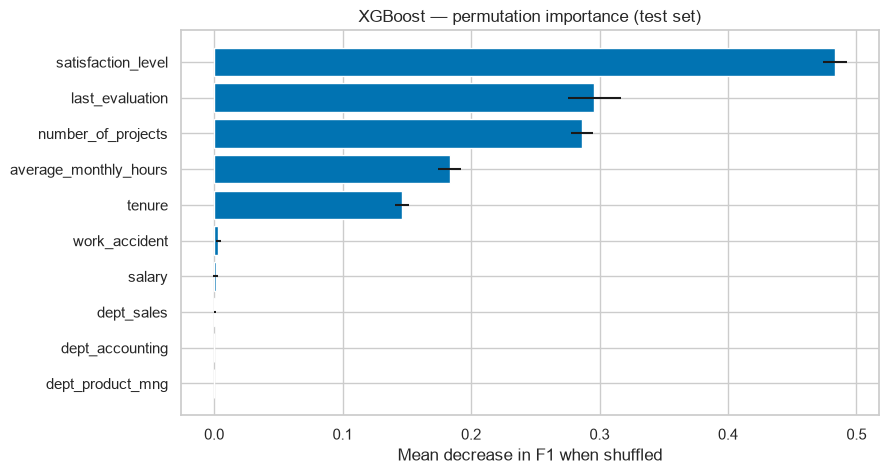

,feature,mean_drop_in_f1,std
0,satisfaction_level,0.4833,0.0094
1,last_evaluation,0.2961,0.0205
2,number_of_projects,0.2864,0.0088
3,average_monthly_hours,0.1833,0.0087
4,tenure,0.1464,0.0056
5,work_accident,0.0034,0.0016
7,salary,0.0011,0.0021
14,dept_sales,0.0008,0.0010
9,dept_accounting,0.0000,0.0000
13,dept_product_mng,0.0000,0.0000


In [32]:
perm = permutation_importance(selected_model, X_test, y_test, scoring="f1",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (
    pd.DataFrame({"feature": X_test.columns,
                  "mean_drop_in_f1": perm.importances_mean,
                  "std": perm.importances_std})
    .sort_values("mean_drop_in_f1", ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance["feature"][::-1], importance["mean_drop_in_f1"][::-1],
        xerr=importance["std"][::-1])
ax.set(title=f"{selected_model_name} — permutation importance (test set)",
       xlabel="Mean decrease in F1 when shuffled", ylabel="")
save_figure(fig, "feature_importance.png")
plt.show()
importance.round(4)

Five features carry almost all of the predictive signal: **satisfaction level**
(shuffling it lowers F1 by 0.48), last evaluation (0.30), number of projects
(0.29), average monthly hours (0.18) and tenure (0.15). Salary, promotion, work
accidents and department contribute almost nothing once these are known,
consistent with the small effect sizes found in §6.

This matches the EDA: turnover is driven by satisfaction and by a combination of
workload, performance and tenure (e.g. overworked high performers), rather than
by pay band or department. These are predictive associations, not causal
effects.

### 9.3 Robustness check: model without satisfaction and evaluation scores

`satisfaction_level` and `last_evaluation` come from surveys and reviews that
may not be available — or may already reflect an employee's decision to leave —
at the moment HR needs a prediction. If the model's performance depended
entirely on them, it would be less useful in practice.

The selected model is re-trained with the same hyperparameters without these
two features and evaluated with the same protocol (CV on train, single test
evaluation).

In [33]:
X_train_reduced = X_train.drop(columns=POTENTIALLY_LEAKY_FEATURES)
X_test_reduced = X_test.drop(columns=POTENTIALLY_LEAKY_FEATURES)

reduced_model = clone(selected_model)
reduced_cv = cross_validate(reduced_model, X_train_reduced, y_train, cv=cv,
                            scoring=CV_SCORING, n_jobs=-1)
reduced_model.fit(X_train_reduced, y_train)

reduced_oof = cross_val_predict(clone(selected_model), X_train_reduced, y_train,
                                cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
reduced_threshold = best_f1_threshold(y_train, reduced_oof)
reduced_test = classification_metrics(
    y_test, reduced_model.predict_proba(X_test_reduced)[:, 1], reduced_threshold)

robustness = pd.DataFrame([
    {"features": "all features", **test_results.loc[selected_model_name].to_dict()},
    {"features": "without satisfaction & evaluation", **reduced_test},
]).set_index("features")
robustness.round(4)

,threshold,precision,recall,f1,accuracy,roc_auc,pr_auc
features,,,,,,,
all features,0.7849,0.9872,0.9257,0.9554,0.9857,0.9845,0.9682
without satisfaction & evaluation,0.7867,0.8792,0.8916,0.8853,0.9616,0.9697,0.9097


Without satisfaction and evaluation scores, test F1 falls from 0.955 to 0.885
and PR-AUC from 0.968 to 0.910: precision drops from 0.987 to 0.879 while recall
stays high (0.892).

The model therefore **still performs well using only workload, tenure and HR
records** (number of projects, monthly hours, tenure, salary, department,
promotion and accidents), which are typically available before an employee
decides to leave. Survey-based scores add value mainly by reducing false alarms.

## 10. Conclusions

**What is associated with turnover?**

- **Satisfaction** is the strongest single factor: leavers report a median of
  0.41 vs 0.69, a large effect (rank-biserial r ≈ −0.49).
- **Workload is non-linear.** Turnover is lowest with 3–4 projects and high with
  2 projects (54%) or 6–7 projects (45–100%); leavers cluster at both low and very
  high monthly hours.
- **Tenure:** turnover peaks around 5 years (45%) and disappears after 7 years.
- **Salary band, promotion and department** show associations in the EDA, but
  add little predictive value once satisfaction, workload and tenure are known.

**Can at-risk employees be identified?**

Yes, on this dataset. A tuned XGBoost model flags 461 of the 498 test-set leavers
(recall 0.93) with very few false alarms (precision 0.99). A random forest
performs equivalently. A model without satisfaction and evaluation scores still
reaches an F1 of 0.89.

**Recommendations for HR**

1. **Monitor workload:** review allocations of employees with 2 projects
   (possible under-use) and 6 or more projects or very high monthly hours
   (possible burnout).
2. **Focus on the 3–5-year tenure window**, where turnover rises sharply:
   career conversations, development plans and promotion reviews.
3. **Run regular satisfaction surveys** and act on low scores; satisfaction is
   the strongest signal available.
4. **Use the model as a decision-support tool**, to prioritise voluntary
   retention conversations with human review — never for automated decisions —
   and validate it on current, real HR data first (see Limitations).

## 11. Limitations and Future Work

**Limitations**

- **Data provenance.** The dataset's collection process is not documented and
  several patterns (e.g. 100% turnover with 7 projects, sharply bounded
  satisfaction/evaluation clusters) suggest it may be synthetic. The very high
  scores should not be expected on real HR data.
- **No employee ID or dates.** Duplicates cannot be verified, and there is no
  time dimension: the model cannot say *when* an employee will leave, and a
  temporal validation (train on past, test on future) is not possible.
- **Timing of features.** Satisfaction and evaluation scores may be measured
  close to the departure; §9.3 quantifies how much the model relies on them.
- **Associations, not causes.** Neither the statistical tests nor feature
  importance show that changing a variable (e.g. reducing workload) would reduce
  turnover; that requires experiments or causal analysis.
- **Fairness not audited.** Error rates across departments and salary bands have
  not been compared.

**Future work**

- Validate on real, time-stamped HR data and use survival analysis to model
  *time to departure*.
- Audit error rates by salary band and department before any deployment.
- Calibrate probabilities so HR can interpret scores as risk levels.
- Translate the threshold into expected cost/benefit with HR's actual
  replacement and retention costs.